# Lensing profiles with the projection selection-bias correction

This notebook shows how to apply `CostanziLensingBias` to a stacked $\Delta\Sigma$ profile. Optical selection preferentially picks clusters embedded in filaments aligned with the line of sight, which biases their stacked lensing signal. Costanzi et al. (2026, Eq. C1) model this as a multiplicative correction,

$$
\Delta\Sigma_{\rm sel}(R)=B_{\rm sel}(R)\,\Delta\Sigma(R),\qquad
B_{\rm sel}(R)=1+A_{\rm sel}\left(\frac{R}{R_{0}}\right)^{\alpha_{\rm sel}}\left[1+\left(\frac{R}{R_{0}}\right)^{\gamma_{\rm sel}}\right]^{(\beta_{\rm sel}-\alpha_{\rm sel})/\gamma_{\rm sel}},
$$

with $R$ in comoving Mpc/$h$. $B_{\rm sel}$ is calibrated per observed richness–redshift bin and applies to the stacked profile *after* integration over the cluster population. The recipe does not apply it, so we multiply its output. The parameters below are illustrative, not fitted.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyccl as ccl

from crow import ClusterShearProfile, kernel, mass_proxy
from crow.cluster_modules.projection_effects import CostanziLensingBias
from crow.properties import ClusterProperty
from crow.recipes.binned_grid import GridBinnedClusterRecipe

cosmo = ccl.Cosmology(Omega_c=0.2607, Omega_b=0.04897, h=0.6766, sigma8=0.8102, n_s=0.9665)
hmf = ccl.halos.MassFuncTinker08(mass_def="200c")

recipe = GridBinnedClusterRecipe(
    cluster_theory=ClusterShearProfile(cosmo, hmf, 4.0, True),  # DeltaSigma, c = 4
    redshift_distribution=kernel.SpectroscopicRedshift(),
    mass_distribution=mass_proxy.MurataUnbinned(14.625862906, 0.6),
    mass_interval=(12.5, 17.0),
    mass_grid_size=60,
    redshift_grid_size=20,
    proxy_grid_size=20,
)
recipe.setup()

# One observed bin: 0.2 < z < 0.4, 10 < lambda_obs < 20
sky_area = 400.0
z_bin, proxy_bin = (0.2, 0.4), (1.0, 1.3)
radius = np.geomspace(0.3, 10.0, 15)  # physical Mpc (CLMM convention)

counts = recipe.evaluate_theory_prediction_counts(z_bin, proxy_bin, sky_area)
delta_sigma = recipe.evaluate_theory_prediction_lensing_profile(
    z_bin, proxy_bin, radius, sky_area, ClusterProperty.DELTASIGMA
) / counts  # stacked (mean) DeltaSigma in Msun / Mpc^2

## Apply the correction

`bsel` returns one row per parameter set. Since our radii are in physical Mpc, pass `radial_units="Mpc"` with `cosmo_h`, and give `reference_redshift` (here the bin center) so the model can convert to comoving Mpc/$h$.

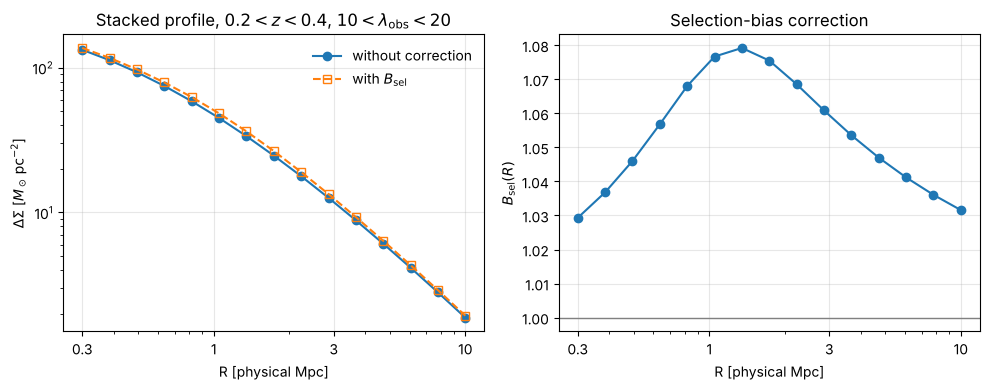

In [2]:
lensing_bias = CostanziLensingBias(
    A_sel=0.10, alpha_sel=0.92, beta_sel=-0.53, gamma_sel=4.1, R0_sel=1.0,
    reference_redshift=np.mean(z_bin),
)
b_sel = lensing_bias.bsel(radius, radial_units="Mpc", cosmo_h=cosmo["h"])[0]
delta_sigma_sel = b_sel * delta_sigma

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.loglog(radius, delta_sigma / 1e12, "-o", label="without correction")
ax1.loglog(radius, delta_sigma_sel / 1e12, "--s", mfc="none", label=r"with $B_{\rm sel}$")
ax1.set(xlabel="R [physical Mpc]", ylabel=r"$\Delta\Sigma$ [$M_\odot\,{\rm pc}^{-2}$]",
        title=rf"Stacked profile, ${z_bin[0]}<z<{z_bin[1]}$, $10<\lambda_{{\rm obs}}<20$")
ax1.legend(frameon=False)
ax2.semilogx(radius, b_sel, "-o")
ax2.axhline(1, color="gray", lw=1)
ax2.set(xlabel="R [physical Mpc]", ylabel=r"$B_{\rm sel}(R)$", title="Selection-bias correction")
for ax in (ax1, ax2):
    ax.set_xticks([0.3, 1, 3, 10], ["0.3", "1", "3", "10"])
    ax.grid(alpha=0.3)
fig.tight_layout()

## Several observed bins

For several observed bins, pass each parameter (and `reference_redshift`) as a 1D array with one entry per bin; `bsel` then returns an array of shape `(n_bins, n_radii)`. Each row then multiplies the stacked $\Delta\Sigma$ of the matching bin. With the default parameters (`A_sel = 0`), $B_{\rm sel}(R) = 1$.

In [ ]:
z_bins = [(0.2, 0.4), (0.4, 0.6), (0.6, 0.8)]
lensing_bias_bins = CostanziLensingBias(
    A_sel=[0.20, 0.15, 0.08],
    alpha_sel=[0.3, 0.5, 0.9],
    beta_sel=[-2.0, -2.0, -2.0],
    gamma_sel=[1.0, 1.0, 1.0],
    R0_sel=[0.8, 1.0, 1.4],
    reference_redshift=[np.mean(zb) for zb in z_bins],
)
b_sel_bins = lensing_bias_bins.bsel(radius, radial_units="Mpc", cosmo_h=cosmo["h"])
print("b_sel_bins shape:", b_sel_bins.shape)  # (n_bins, n_radii)

fig, ax = plt.subplots(figsize=(5, 4))
for (zlo, zhi), b in zip(z_bins, b_sel_bins):
    ax.semilogx(radius, b, "-o", label=rf"${zlo}<z<{zhi}$")
ax.axhline(1, color="gray", lw=1)
ax.set(xlabel="R [physical Mpc]", ylabel=r"$B_{\rm sel}(R)$", title="One correction per observed bin")
ax.set_xticks([0.3, 1, 3, 10], ["0.3", "1", "3", "10"])
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()